# Country vs metro: are country draftees overlooked?

This notebook runs the analysis set out in the
[pre-registration](../docs/preregistration_country_metro.md), which was committed
before any outcome was compared between country and metro players.

**Question:** at the same pick number, do Victorian draftees from country
under-18 clubs beat their pick by more than those from metro clubs?

**Deviation:** the pre-registration gave the metro group as 320 picks. The
correct figure is 309. The power check had double-counted players who were
drafted twice. The group definitions are unchanged, and an erratum was added
to the plan before any outcomes were compared.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import add_residuals, bootstrap
from afl.datasets import draft_outcomes
from afl.draft_charts import BLUE, GREY, INK, ORANGE, TITLE, apply_style

N_BOOT = 2000
pd.set_option("display.width", 200)
apply_style()

COUNTRY = ["Murray U18", "Gippsland U18", "North Ballarat U18", "Bendigo U18"]
METRO = ["Oakleigh U18", "Sandringham U18", "Dandenong U18", "Calder U18",
         "Eastern U18", "Northern U18", "Western U18"]
GEELONG = ["Geelong U18"]
COLOURS = {"Country": ORANGE, "Metro": BLUE, "Geelong": GREY}


def fmt(result, unit=" games"):
    est, low, high = result
    return f"{est:+.1f}{unit}  [95% CI {low:+.1f} to {high:+.1f}]"


def country_minus_metro(data, col="resid_games"):
    return (data.loc[data["group"] == "Country", col].mean()
            - data.loc[data["group"] == "Metro", col].mean())

## 1. Data

The baseline (expected games at each pick) comes from **all** 2005–2018 picks
1–80, from every state. The Victorian groups are then picked out of that table,
so every player is compared with the whole league.

In [2]:
all_picks = add_residuals(draft_outcomes(2005, 2018, windows=(8, 10)), "games_8")

group_of = {**{c: "Country" for c in COUNTRY}, **{c: "Metro" for c in METRO},
            **{c: "Geelong" for c in GEELONG}}
all_picks["group"] = all_picks["pathway_club"].map(group_of)
vic = all_picks[all_picks["group"].notna()].copy()
main = vic[vic["group"].isin(["Country", "Metro"])]

print(vic["group"].value_counts().to_string())
print(f"\nAll picks 1-80 used for the baseline: {len(all_picks)}")

group
Metro      309
Country    113
Geelong     55

All picks 1-80 used for the baseline: 1004


### Descriptive: who are these players and where are they picked?

In [3]:
vic.groupby("group").agg(
    picks=("pick", "size"),
    average_pick=("pick", "mean"),
    share_top_20=("pick", lambda p: (p <= 20).mean()),
    average_age=("age", "mean"),
    average_height=("height_cm", "mean"),
    mature_age=("mature_age", "sum"),
    bid_matched=("bid_matched", "sum"),
).loc[["Country", "Metro", "Geelong"]].round(2)

,picks,average_pick,share_top_20,average_age,average_height,mature_age,bid_matched
group,,,,,,,
Country,113,35.94,0.33,18.58,189.35,8,3
Metro,309,32.78,0.33,18.65,188.47,18,20
Geelong,55,33.42,0.38,18.36,186.38,3,5


## 2. Primary test

Mean residual games (first 8 seasons, against the league average at the pick)
for country picks, minus the same for metro picks.

In [4]:
primary = bootstrap(main, country_minus_metro, n=N_BOOT)

if primary[1] > 0:
    reading = "SUPPORTED: country players beat their pick by more (undervalued)"
elif primary[2] < 0:
    reading = "CONTRADICTED: country players beat their pick by less (overvalued)"
else:
    reading = "INCONCLUSIVE (interval includes 0)"

print(f"Country minus metro: {fmt(primary)}")
print(f"Pre-registered reading: {reading}")
for name in ["Country", "Metro", "Geelong"]:
    g = vic[vic["group"] == name]
    print(f"  {name:8} mean residual {g['resid_games'].mean():+5.1f}  "
          f"(games {g['games'].mean():.1f} vs expected {g['expected_games'].mean():.1f}, n={len(g)})")

Country minus metro: +1.5 games  [95% CI -8.4 to +11.4]
Pre-registered reading: INCONCLUSIVE (interval includes 0)
  Country  mean residual  -0.2  (games 66.9 vs expected 67.0, n=113)
  Metro    mean residual  -1.7  (games 68.7 vs expected 70.4, n=309)
  Geelong  mean residual  +3.5  (games 73.0 vs expected 69.5, n=55)


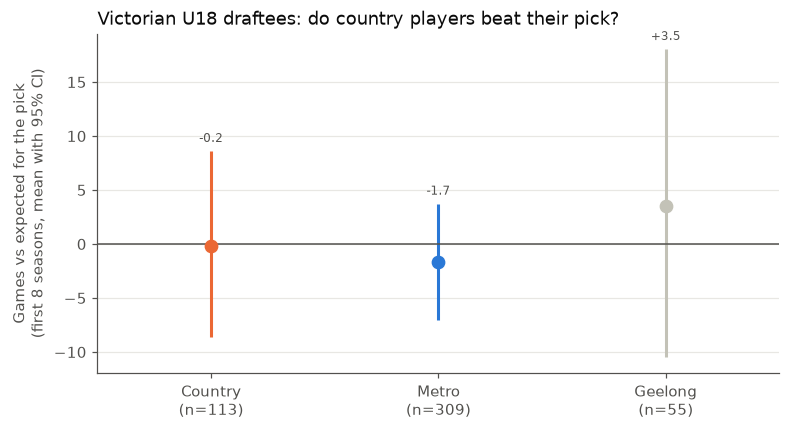

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
names = ["Country", "Metro", "Geelong"]
results = [bootstrap(vic[vic["group"] == n], lambda d: d["resid_games"].mean(), n=N_BOOT) for n in names]
x = np.arange(len(names))
for xi, name, (est, low, high) in zip(x, names, results):
    ax.errorbar(xi, est, yerr=[[est - low], [high - est]], fmt="o", color=COLOURS[name],
                markersize=8, capsize=0, elinewidth=2)
    ax.annotate(f"{est:+.1f}", (xi, high), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(x, [f"{n}\n(n={(vic['group'] == n).sum()})" for n in names])
ax.set_xlim(-0.5, len(names) - 0.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Games vs expected for the pick\n(first 8 seasons, mean with 95% CI)")
ax.set_title("Victorian U18 draftees: do country players beat their pick?", loc="left", color=TITLE)
plt.show()

## 3. Secondary checks (reported, not used to judge the primary test)

The baseline stays the league-wide one throughout. The checks only change which
Victorian players are compared. The 10-season check recomputes the baseline
from all 2005–2016 picks, because that window is only complete for those drafts.

In [6]:
rows = []
for col, label in [("bust", "Bust (<50 games)"), ("massive_bust", "Massive bust (<20 games)")]:
    for name in ["Country", "Metro", "Geelong"]:
        g = vic[vic["group"] == name]
        est, low, high = bootstrap(g, lambda d: d[f"resid_{col}"].mean() * 100, n=N_BOOT)
        rows.append({"outcome": label, "group": name, "actual": f"{g[col].mean():.0%}",
                     "expected at their picks": f"{g[f'expected_{col}'].mean():.0%}",
                     "difference (pts)": round(est, 1), "CI": f"{low:+.1f} to {high:+.1f}"})
print("Secondary 1: bust rates")
pd.DataFrame(rows)

Secondary 1: bust rates


,outcome,group,actual,expected at their picks,difference (pts),CI
0,Bust (<50 games),Country,45%,47%,-1.9,-9.9 to +5.7
1,Bust (<50 games),Metro,47%,44%,3.0,-1.8 to +7.8
2,Bust (<50 games),Geelong,40%,46%,-6.0,-18.8 to +5.9
3,Massive bust (<20 games),Country,32%,31%,0.5,-6.9 to +7.7
4,Massive bust (<20 games),Metro,30%,29%,0.9,-3.7 to +5.7
5,Massive bust (<20 games),Geelong,31%,29%,1.6,-9.9 to +13.8


In [7]:
ten = add_residuals(draft_outcomes(2005, 2016, windows=(10,)), "games_10")
ten["group"] = ten["pathway_club"].map(group_of)

checks = {
    "2. Geelong counted as country":
        vic.assign(group=vic["group"].replace({"Geelong": "Country"})),
    "3. Excluding mature-age (19.0+)":
        main[main["age"].notna() & ~main["mature_age"]],
    "4. Excluding bid-matched picks":
        main[~main["bid_matched"]],
    "5. 10-season window (2005-2016 drafts)":
        ten[ten["group"].isin(["Country", "Metro"])],
    "6a. Picks 1-40":
        main[main["pick"] <= 40],
    "6b. Picks 41-80":
        main[main["pick"] > 40],
}
rows = []
for name, data in checks.items():
    est, low, high = bootstrap(data, country_minus_metro, n=N_BOOT)
    rows.append({"check": name,
                 "country n": int((data["group"] == "Country").sum()),
                 "metro n": int((data["group"] == "Metro").sum()),
                 "country minus metro": round(est, 1), "CI low": round(low, 1), "CI high": round(high, 1),
                 "includes 0": low <= 0 <= high})
rows.insert(0, {"check": "Primary (as planned)", "country n": int((main["group"] == "Country").sum()),
                "metro n": int((main["group"] == "Metro").sum()),
                "country minus metro": round(primary[0], 1), "CI low": round(primary[1], 1),
                "CI high": round(primary[2], 1), "includes 0": primary[1] <= 0 <= primary[2]})
pd.DataFrame(rows).set_index("check")

,country n,metro n,country minus metro,CI low,CI high,includes 0
check,,,,,,
Primary (as planned),113,309,1.5,-8.4,11.4,True
2. Geelong counted as country,168,309,2.7,-6.2,12.3,True
3. Excluding mature-age (19.0+),105,291,-0.4,-10.4,10.5,True
4. Excluding bid-matched picks,110,289,3.3,-6.7,13.1,True
5. 10-season window (2005-2016 drafts),100,255,5.2,-9.0,18.9,True
6a. Picks 1-40,61,199,6.3,-7.5,19.7,True
6b. Picks 41-80,52,110,-3.9,-17.7,10.4,True


## 4. Descriptive: each under-18 club

This shows whether one club drives a group's result. With 18–64 picks per club,
the intervals are wide, so it is **not** a ranking of clubs' talent programmes.

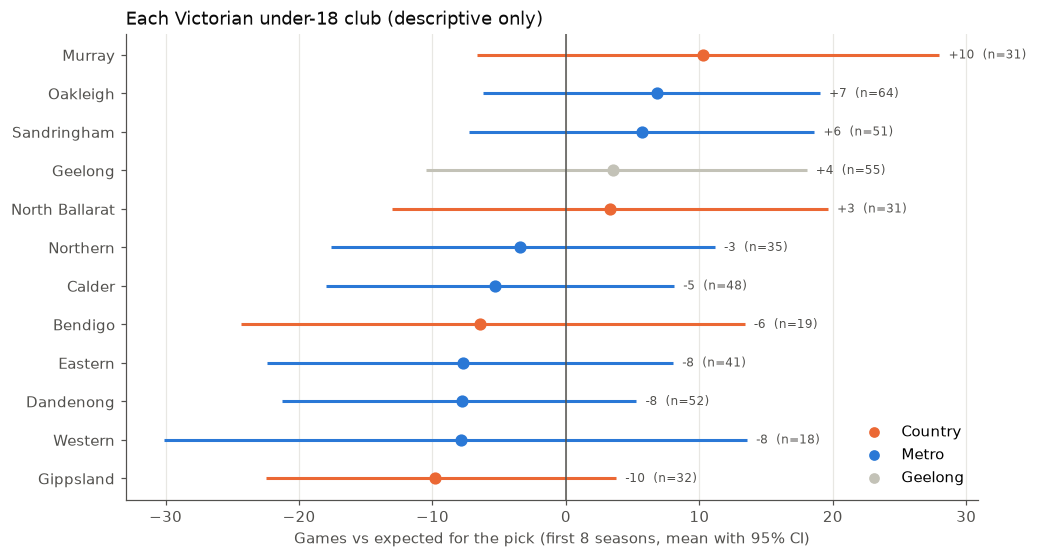

,group,picks,average pick,residual,low,high,bust rate,expected bust
club,,,,,,,,
Gippsland,Country,32,34.12,-9.83,-22.44,3.76,0.50,0.45
Western,Metro,18,22.89,-7.88,-30.09,13.57,0.50,0.37
Dandenong,Metro,52,33.08,-7.77,-21.30,5.28,0.54,0.44
Eastern,Metro,41,35.59,-7.74,-22.40,8.03,0.51,0.47
Bendigo,Country,19,36.79,-6.47,-24.34,13.40,0.53,0.47
Calder,Metro,48,35.73,-5.35,-18.01,8.10,0.54,0.47
Northern,Metro,35,28.97,-3.45,-17.63,11.16,0.43,0.41
North Ballarat,Country,31,37.81,3.27,-13.01,19.63,0.48,0.50
Geelong,Geelong,55,33.42,3.52,-10.48,18.04,0.40,0.46


In [8]:
rows = []
for club in COUNTRY + GEELONG + METRO:
    g = vic[vic["pathway_club"] == club]
    est, low, high = bootstrap(g, lambda d: d["resid_games"].mean(), n=N_BOOT)
    rows.append({"club": club.replace(" U18", ""), "group": group_of[club], "picks": len(g),
                 "average pick": g["pick"].mean(), "residual": est, "low": low, "high": high,
                 "bust rate": g["bust"].mean(), "expected bust": g["expected_bust"].mean()})
clubs = pd.DataFrame(rows).sort_values("residual")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(clubs))
for yi, row in zip(y, clubs.itertuples()):
    ax.errorbar(row.residual, yi, xerr=[[row.residual - row.low], [row.high - row.residual]],
                fmt="o", color=COLOURS[row.group], markersize=7, capsize=0, elinewidth=2)
    ax.annotate(f"{row.residual:+.0f}  (n={row.picks})", (row.high, yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, clubs["club"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Games vs expected for the pick (first 8 seasons, mean with 95% CI)")
ax.set_title("Each Victorian under-18 club (descriptive only)", loc="left", color=TITLE)
for name, colour in COLOURS.items():
    ax.scatter([], [], color=colour, label=name)
ax.legend(frameon=False, loc="lower right")
plt.show()

clubs.set_index("club").round(2)

# Results

## Primary test (pre-registered)

**Inconclusive, and close to zero.** Country picks beat their pick by **1.5 more
games than metro picks over 8 seasons (95% CI −8.4 to +11.4)**. Both groups
landed almost exactly on what their picks predicted: country −0.2 games, metro
−1.7.

That isn't proof of no difference. But the interval is narrow enough to say
something useful: **a country edge bigger than about 11 games, or a deficit
bigger than about 8, is unlikely.** The pre-registration estimated about 80% power
for a 15-game difference, and nothing near that size showed up.

## Secondary checks

- **Every check agrees.** All six versions give a difference between −3.9 and
  +6.3 games, and every interval includes 0:
  - Geelong counted as country
  - excluding mature-age players
  - excluding bid-matched picks
  - a 10-season window
  - early picks only
  - late picks only
- **Bust rates match expectations in both groups.** Busts (under 50 games):
  country 45% vs 47% expected, metro 47% vs 44%. Massive busts: 32% vs 31%
  country, 30% vs 29% metro.
- **No sign that country players are picked later, either.** Country and metro
  draftees had a similar average pick (36 vs 33) and the same share in the top
  20 (33% each).

## Each club (descriptive)

No individual club stands clearly apart. Every interval includes 0. The highest
(Murray, +10) and lowest (Gippsland, −10) are **both country clubs**, so
"country" doesn't behave as one group with a shared edge.

## What this adds up to

Among Victorian under-18 draftees, **clubs appear to have valued country and
metro players accurately** once they were drafted. Whatever scouting
disadvantages country players face, they don't show up as country draftees
beating (or missing) their draft position.

That's a useful answer for a recruiter, and a good contrast with the
mature-age result: the "overlooked group" idea held there, but not here.

## What this can't answer

- **Whether country players are under-drafted to begin with.** We only see
  players who were drafted. Comparing each zone's share of draftees with its
  share of junior footballers would need participation figures we don't have.
- **Other states.** SA and WA country players come through metro-based state-league
  clubs, so they'd need home towns looked up player by player.